# NN_L4_conv_edges

**Sobel edge filters and a mean filter applied by convolution (padding 1) to a real 64 x 64 Sentinel-2 tile (EuroSAT, class Highway).**

Neural Networks and Deep Learning (NN), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L4/NN_L4_conv_edges/NN_L4_conv_edges.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Output size $\lfloor (H+2p-k)/s\rfloor+1$ and three fixed 3 x 3 kernels on a real tile.

k=3, p=1, s=1 = 64   [conv.out_same]
k=3, p=0, s=1 = 62   [conv.out_valid]
k=3, p=1, s=2 = 32   [conv.out_s2]


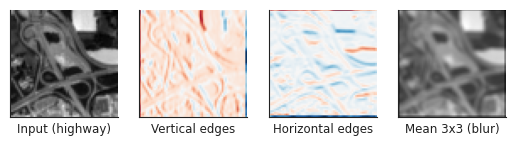

In [3]:
VISION = REPO + 'data/raw/vision' if os.path.isdir(REPO + 'data') else 'vision'
os.makedirs(VISION, exist_ok=True)
import torch, torch.nn.functional as F, torchvision
from PIL import Image
torchvision.datasets.EuroSAT(VISION, download=True)
d = os.path.join(VISION, 'eurosat', '2750', 'Highway')
img = np.asarray(Image.open(os.path.join(d, sorted(os.listdir(d))[5])).convert('RGB')).astype(np.float32).mean(2) / 255
Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ker = [Kx, Kx.T, np.ones((3, 3), np.float32) / 9]
out = [F.conv2d(torch.tensor(img)[None, None], torch.tensor(k)[None, None], padding=1)[0, 0].numpy() for k in ker]
osz = lambda H, k, p, s: (H + 2 * p - k) // s + 1
show('conv.out_same', 'k=3, p=1, s=1', osz(64, 3, 1, 1))
show('conv.out_valid', 'k=3, p=0, s=1', osz(64, 3, 0, 1))
show('conv.out_s2', 'k=3, p=1, s=2', osz(64, 3, 1, 2))
fig, axes = plt.subplots(1, 4, figsize=(6.4, 1.9))
for ax, im, cm, l in zip(axes, [img] + out, ['gray', 'RdBu_r', 'RdBu_r', 'gray'],
                             ['Input (highway)', 'Vertical edges', 'Horizontal edges', 'Mean 3x3 (blur)']):
    ax.imshow(im, cmap=cm); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(l, fontsize=8.5)
fig.savefig('conv_edges.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()